# Script para cálculo de fluxo do gerador no Mobipix 003 (perov e pips)

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
from glob import glob
import matplotlib.pylab as pl
from PIL import Image
import matplotlib as mpl
from scipy.optimize import curve_fit
from scipy.integrate import quad
import h5py
import os
from matplotlib import colors
from tqdm import tqdm
import pandas as pd

In [66]:
#carregar o arquivo a ser analisado

FILE = r'C:\Users\julia.fukunaga\Documents\Mobi lcoc\20260728_gearador_direto_50kV_10uA_017.h5'

f = h5py.File(FILE, 'r')

imagens = f['entry/data/data']

fluxo = np.array(imagens, dtype = np.uint32)

In [7]:
#carregar o arquivo de ruido

img = r'C:\Users\julia.fukunaga\Documents\Mobi lcoc\ruido_th50_1s_100img_24b_001.h5'

g = h5py.File(img, 'r')

ruido = g['entry/data/data']

ruido = np.array(ruido, dtype = np.uint32)

In [8]:
#cria uma mascara para o ruido

mask = np.zeros([512,512], dtype = int)

mask[2:254,2:254]=1      #linhas de junçao dos asics
mask[2:254,258:510]=1
mask[258:510,2:254]=1
mask[258:510,258:510]=1

px_sat_x = []
px_sat_y = []

for k in tqdm(range(0,10),'carregando resultados'):
    for i in range(0,512):
        for j in range(0,512):
            if ruido[k,j,i] > 10:
                px_sat_x.append(i)
                px_sat_y.append(j)

px_sat_x = np.array(px_sat_x)
px_sat_y = np.array(px_sat_y)

carregando resultados: 100%|██████████| 10/10 [00:01<00:00,  9.00it/s]


Text(0.5, 1.0, 'Mask Mobipix 003 - Fluxo do gerador direto')

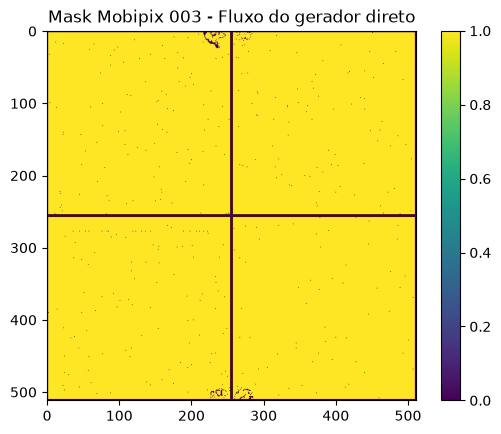

In [9]:
for n in range(0,int(px_sat_x.shape[0])):
    mask[px_sat_y[n],px_sat_x[n]] = 0


plt.figure()
plt.imshow(mask, vmin=0, vmax=1) #v é a escala
plt.colorbar()
plt.title('Mask Mobipix 003 - Fluxo do gerador direto')

(512, 512)


Text(0.5, 1.0, 'Fluxo gerador direto - imagem limpa')

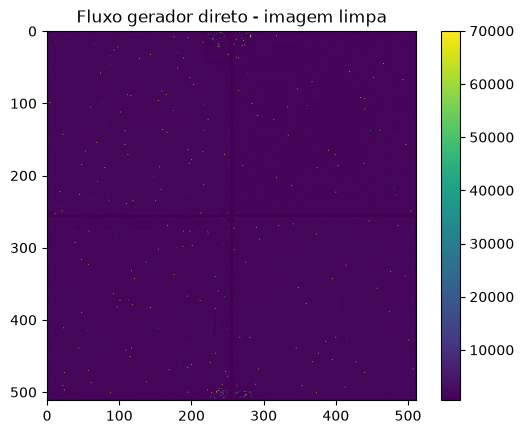

In [67]:
#aplica a mascara na imagem 

img_limpa = fluxo[0]*mask

print(img_limpa.shape)

plt.figure()
plt.imshow(img_limpa, vmin=500, vmax=70000) #limites definidos a partir da visualizaçao do silx
plt.colorbar()
plt.title('Fluxo gerador direto - imagem limpa')

#plt.savefig(
#    r"C:\Users\julia.fukunaga\Documents\fluxo_CsPbBr3_mobi.png",
#    dpi=600,
#    bbox_inches="tight"
#)

In [68]:
#calculo de fluxo medio do sensor inteiro (sem roi) e normalizado pela area total

x1_roi = 300
x2_roi = 510
y1_roi = 300
y2_roi = 500


Fluxo_med = (np.sum(fluxo[:,y1_roi:y2_roi,x1_roi:x2_roi])/fluxo.shape[0])
print('Fluxo integrado =',np.round(Fluxo_med,2),'ph/s')
print()

Fluxo_area = Fluxo_med/((x2_roi-x1_roi)*(y2_roi-y1_roi)*0.055**2)
print('Fluxo normalizado pela área =',np.round(Fluxo_area,2),'ph/mm².s')

Fluxo integrado = 81850913.1 ph/s

Fluxo normalizado pela área = 644241.74 ph/mm².s


Text(0.5, 1.0, 'ROI fluxo')

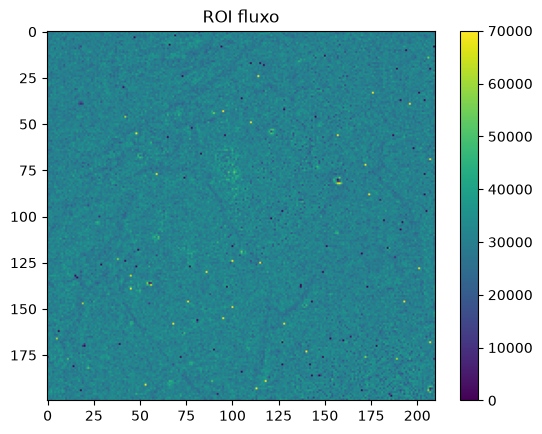

In [15]:
plt.figure()
plt.imshow(fluxo[0,y1a_roi:y2a_roi,x1a_roi:x2a_roi], vmin=0, vmax=70000) #posição para analisar o fluxo flat
plt.colorbar()
plt.title('ROI fluxo')

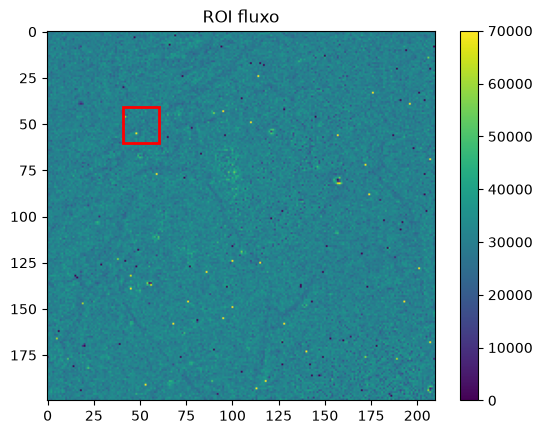

In [219]:
from matplotlib.patches import Rectangle

fig, ax = plt.subplots()

ax.imshow(
    fluxo[0, y1a_roi:y2a_roi, x1a_roi:x2a_roi],
    vmin=0,
    vmax=70000
)

# centro da região 19x19
xc = 50
yc = 50

# canto superior esquerdo
x_ini = xc - 9
y_ini = yc - 9

ret = Rectangle(
    (x_ini, y_ini),  # canto superior esquerdo
    19,              # largura
    19,              # altura
    edgecolor='red',
    facecolor='none',
    linewidth=2
)

ax.add_patch(ret)

plt.colorbar(ax.images[0], ax=ax)
plt.title('ROI fluxo')

plt.savefig(
    r"C:\Users\julia.fukunaga\Documents\fluxo_roi_perov.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

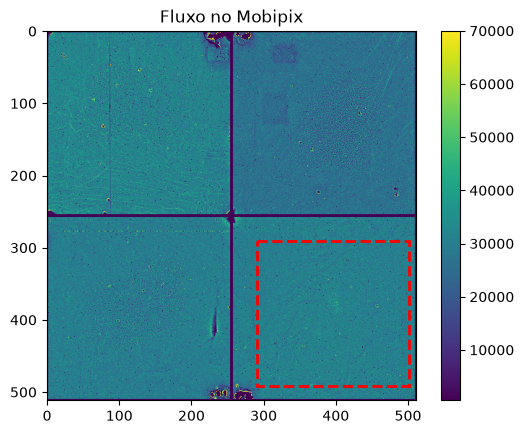

In [228]:
#plt.figure()
#plt.imshow(img_limpa, vmin=500, vmax=70000) #limites definidos a partir da visualizaçao do silx
#plt.colorbar()
#plt.title('Fluxo gerador direto - imagem limpa')

fig, ax = plt.subplots()

ax.imshow(img_limpa, vmin=500, vmax=70000)

# centro da região 19x19
xc = 300
yc = 300

# canto superior esquerdo
x_ini = xc - 9
y_ini = yc - 9

ret = Rectangle(
    (x_ini, y_ini),  # canto superior esquerdo
    210,              # largura
    200,              # altura
    edgecolor='red',
    facecolor='none',
    linewidth=2,
    linestyle='--'
)

ax.add_patch(ret)

plt.colorbar(ax.images[0], ax=ax)
plt.title('Fluxo no Mobipix')

#plt.savefig(
#    r"C:\Users\julia.fukunaga\Documents\Experimento Mobi Perov Pips\fluxo_mobi_area_roi.png",
#    dpi=600,
#    bbox_inches="tight"
#)
plt.show()

In [28]:
#CUIDADO PARA NÃO LIMPAR A LISTA

#dados = []

dados[3] = Fluxo_med.item(), Fluxo_area.item()  #substitui o dado em uma posicao especifica

In [69]:
#listar todos os dados

dados.append((Fluxo_med.item(), Fluxo_area.item()))  #comentado por segurança 

print(dados)
print(len(dados))

#dados.pop(5) #remove dados especificos de uma posicao da lista

[(1299124464.3166666, 10225300.781713236), (1205629391.4333334, 9489408.826708646), (1114287940.9666667, 8770467.854912765), (1020371986.3, 8031263.174340811), (932157724.65, 7336936.046044864), (839749916.0333333, 6609601.857798766), (745268925.9833333, 5865949.830644104), (648305900.075, 5102761.905352224), (553499699.4666667, 4356550.172897809), (456762111.18333334, 3595136.648432376), (360727895.325, 2839259.3099173554), (264534456.63333333, 2082128.7417027417), (170322535.71666667, 1340594.5353535353), (81850913.1, 644241.7402597403)]
14


In [79]:
#calculo do fluxo integrado para a area da perov

area_perov = 1.095  # mm²

fluxos_perov = []

for fluxo_med, fluxo_area in dados:
    fluxos_perov.append(fluxo_area * area_perov)

fluxos_perov_pixel = [x/(55*55) for x in fluxos_perov] #area do pixel em um

#calculo de fluxo por pixel para 5 cm

d0=20  #distancia da medida em cm
d=5  #nova distancia


fluxo_distancia = [y*((d0/d)**2) for y in fluxos_perov_pixel]
print(fluxo_distancia)

df = pd.DataFrame(
    dados,
    columns=[
        "Fluxo integrado (ph/s)",
        "Fluxo normalizado pela área (ph/mm².s)"
    ]
)


df["Fluxo na perovskita (ph/s)"] = fluxos_perov

df["Fluxo na perovskita pela área do pixel em 20 cm (ph/pixel.s)"] = fluxos_perov_pixel

df["Fluxo na perovskita pela área do pixel em 5 cm (ph/pixel.s)"] = fluxo_distancia

print(df)

[59222.23791590608, 54960.14632857371, 50796.23035308153, 46514.95233535571, 42493.59323196893, 38281.06596649071, 33974.0300935156, 29553.84746504825, 25231.98645592384, 20822.08068778024, 16444.23904454614, 12059.139026324638, 7764.369011369897, 3731.2777816035205]
    Fluxo integrado (ph/s)  Fluxo normalizado pela área (ph/mm².s)  \
0             1.299124e+09                            1.022530e+07   
1             1.205629e+09                            9.489409e+06   
2             1.114288e+09                            8.770468e+06   
3             1.020372e+09                            8.031263e+06   
4             9.321577e+08                            7.336936e+06   
5             8.397499e+08                            6.609602e+06   
6             7.452689e+08                            5.865950e+06   
7             6.483059e+08                            5.102762e+06   
8             5.534997e+08                            4.356550e+06   
9             4.567621e+08      

In [83]:
# salvar em csv
df.to_csv(
    r"C:\Users\julia.fukunaga\Documents\Experimento Mobi Perov Pips\fluxo_mobi_perov3.csv", 
    sep=";",
    decimal=",",
    index=False)

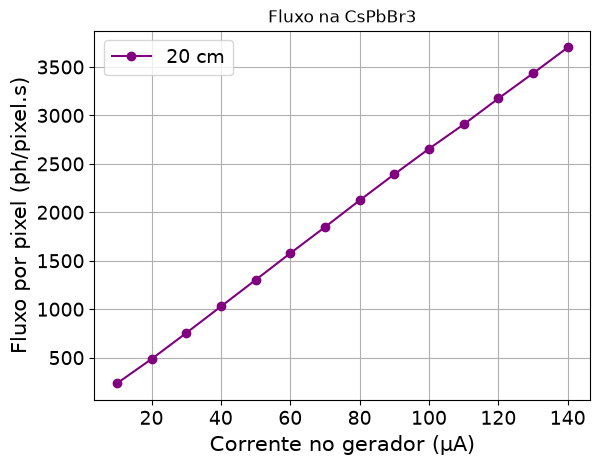

In [86]:
#plot de fluxo por corrente do gerador
correntes = [140,130,120,110,100,90,80,70,60,50,40,30,20,10]

plt.plot(
    correntes,
    fluxos_perov_pixel,
    'o-',
    color='purple',
    label = '20 cm'
)

#plt.plot(
#    correntes,
#    fluxo_distancia,
#    'o-',
#    color='green',
#    label = '5 cm'
#)

plt.ylabel('Fluxo por pixel (ph/pixel.s)', fontsize=15)
plt.xlabel('Corrente no gerador (µA)', fontsize=15)
plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('Fluxo na CsPbBr3')
plt.grid(True)

plt.savefig(
    r"C:\Users\julia.fukunaga\Documents\Experimento Mobi Perov Pips\fluxo_CsPbBr3_20cm.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

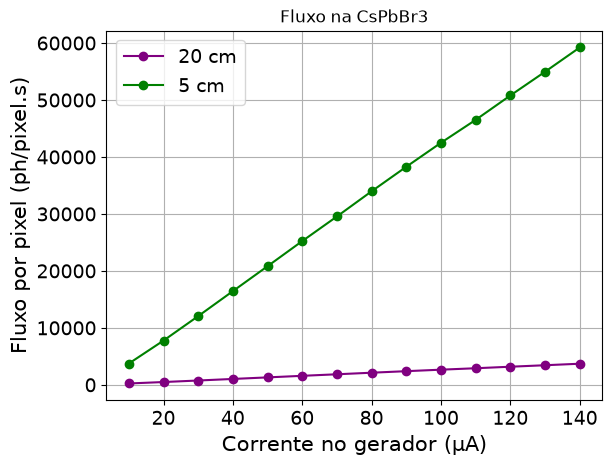

In [88]:
#plot de fluxo por corrente do gerador
correntes = [140,130,120,110,100,90,80,70,60,50,40,30,20,10]

plt.plot(
    correntes,
    fluxos_perov_pixel,
    'o-',
    color='purple',
    label = '20 cm'
)

plt.plot(
    correntes,
    fluxo_distancia,
    'o-',
    color='green',
    label = '5 cm'
)

plt.ylabel('Fluxo por pixel (ph/pixel.s)',fontsize=15)
plt.xlabel('Corrente no gerador (µA)',fontsize=15)
plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('Fluxo na CsPbBr3')
plt.grid(True)

plt.savefig(
    r"C:\Users\julia.fukunaga\Documents\Experimento Mobi Perov Pips\fluxo_CsPbBr3_distancias.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [73]:
#calculo do fluxo integrado para a area do pips

area_pips = 150  # mm²

fluxos_pips = []

for fluxo_med, fluxo_area in dados:
    fluxos_pips.append(fluxo_area * area_pips)

fluxos_pips_pixel = [x/(55*55) for x in fluxos_pips] #area do pixel em um

d0=20  #distancia da medida em cm
d=5  #nova distancia


fluxo_distancia_pips = [y*((d0/d)**2) for y in fluxos_pips_pixel]
print(fluxo_distancia_pips)

df_pips = pd.DataFrame(
    dados,
    columns=["Fluxo integrado (ph/s)",
            "Fluxo normalizado pela área (ph/mm².s)"]
)

df_pips["Fluxo no PIPS (ph/s)"] = fluxos_pips

df_pips["Fluxo no PIPS pela área do pixel em 20 cm (ph/pixel.s)"] = fluxos_pips_pixel

df_pips["Fluxo no PIPS pela área do pixel em 5 cm (ph/pixel.s)"] = fluxo_distancia_pips
print(df_pips)

[8112635.3309460385, 7528787.168297769, 6958387.719600211, 6371911.27881585, 5821040.168762866, 5243981.639245302, 4653976.725139123, 4048472.255486062, 3456436.500811485, 2852339.820243868, 2252635.4855542653, 1651936.8529211835, 1063612.1933383422, 511133.94268541376]
    Fluxo integrado (ph/s)  Fluxo normalizado pela área (ph/mm².s)  \
0             1.299124e+09                            1.022530e+07   
1             1.205629e+09                            9.489409e+06   
2             1.114288e+09                            8.770468e+06   
3             1.020372e+09                            8.031263e+06   
4             9.321577e+08                            7.336936e+06   
5             8.397499e+08                            6.609602e+06   
6             7.452689e+08                            5.865950e+06   
7             6.483059e+08                            5.102762e+06   
8             5.534997e+08                            4.356550e+06   
9             4.567621e+08   

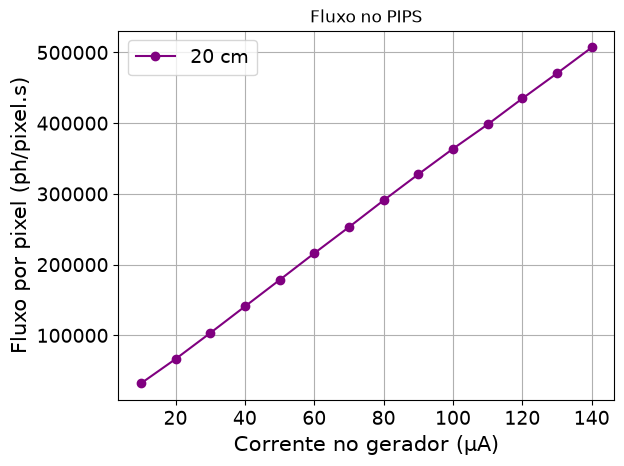

In [76]:
correntes = [140,130,120,110,100,90,80,70,60,50,40,30,20,10]

plt.plot(
    correntes,
    fluxos_pips_pixel,
    'o-',
    color='purple',
    label = '20 cm'
)

#plt.plot(
#    correntes,
#    fluxo_distancia_pips,
#    'o-',
#    color='green',
#    label = '5 cm'
#)

plt.ylabel('Fluxo por pixel (ph/pixel.s)',fontsize=15)
plt.xlabel('Corrente no gerador (µA)',fontsize=15)
plt.legend(fontsize=14)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.title('Fluxo no PIPS')
plt.grid(True)

plt.savefig(
    r"C:\Users\julia.fukunaga\Documents\Experimento Mobi Perov Pips\fluxo_PIPS_20cm.png",
    dpi=600,
    bbox_inches="tight"
)
plt.show()

In [145]:
# salvar em csv
#df_pips.to_csv(
#    r"C:/Users/julia.fukunaga/Documents/Mobi lcoc/fluxo_mobi_pips2.csv", 
#    sep=";",
#    decimal=",",
#    index=False)